# Pan Cancer Survival Risk Modelling from TCGA Gene Expression (revised analysis)

Supporting notebook for manuscript IMU D 26 00709, revision 1. It regenerates every single split
figure and number in the revised manuscript. Results over repeated cross validation, the outcome
sensitivity analyses and the censoring aware Cox models over repeated splits are produced by
`pancancer_revision.py`; this notebook imports its cohort and pipeline code so that both use the
same definitions.

**Data.** UCSC Xena TCGA Pan Cancer (PANCAN) gene expression, the PanCanAtlas EB++ batch adjusted
RSEM matrix (log2(x + 1); 20,531 genes by 11,069 samples), and the TCGA Pan Cancer Clinical Data
Resource as distributed by Xena (`tcga_survival.tsv`).

**Unit of analysis.** The expression matrix is keyed by sample. One primary tumor sample is kept per
patient (sample type 01, or 03 for LAML), so normal tissue, metastatic and recurrent samples are
removed and every patient appears once. Every count below is a count of patients.

**Leakage control.** The train/test split comes first. Imputation, variance filtering,
standardization, PCA and L1 selection are fitted on training data only and use gene expression
only; tumor type and clinical variables are added after PCA.

Set `PANCAN_DATA_DIR` to the folder holding the two data files and `PANCAN_CODE_DIR` to the folder
holding `pancancer_revision.py` (both default to the current folder).

## 1. Environment

In [1]:
import os, sys, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.stats as st

warnings.filterwarnings("ignore")
os.environ["PYTHONWARNINGS"] = "ignore"

DATA_DIR = Path(os.environ.get("PANCAN_DATA_DIR", "."))
CODE_DIR = Path(os.environ.get("PANCAN_CODE_DIR", "."))
sys.path.insert(0, str(CODE_DIR))
import pancancer_revision as pr          # shared cohort, labelling and pipeline code

RANDOM_STATE = pr.SEED
EXPR_PATH = DATA_DIR / "tcga_gene_expression.tsv"
SURV_PATH = DATA_DIR / "tcga_survival.tsv"
FIG_DIR = Path("report_figures_revised"); FIG_DIR.mkdir(exist_ok=True)
TAB_DIR = Path("notebook_tables"); TAB_DIR.mkdir(exist_ok=True)

plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 300, "savefig.bbox": "tight",
    "font.size": 9, "axes.titlesize": 10, "axes.labelsize": 9,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "grid.linewidth": 0.5,
})


def save_fig(name):
    # write the current figure as PNG and PDF
    for ext in ("png", "pdf"):
        plt.savefig(FIG_DIR / f"{name}.{ext}")


import sklearn, lifelines, sksurv
print(f"python {sys.version.split()[0]} | numpy {np.__version__} | pandas {pd.__version__} | "
      f"scikit-learn {sklearn.__version__} | lifelines {lifelines.__version__} | "
      f"scikit-survival {sksurv.__version__}")

python 3.9.6 | numpy 2.0.2 | pandas 2.3.3 | scikit-learn 1.5.2 | lifelines 0.30.0 | scikit-survival 0.23.1


In [2]:
from sklearn.base import clone
from sklearn.calibration import calibration_curve
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (ConfusionMatrixDisplay, classification_report, confusion_matrix,
                             roc_auc_score, roc_curve)
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.preprocessing import StandardScaler

## 2. Data and patient flow

One row per patient on both sides. The patient flow table (Figure S1) lists every removal step.

In [3]:
Xdf, clin, clin_full = pr.build_cohort(str(EXPR_PATH), str(SURV_PATH), str(TAB_DIR))
flow = pd.read_csv(TAB_DIR / "R2_4_patient_flow.csv")
print(flow.to_string(index=False))
print(f"\nExpression matrix after selection: {Xdf.shape[0]:,} patients by {Xdf.shape[1]:,} genes")
print(f"Missing expression values retained for imputation: {int(np.isnan(Xdf.values).sum()):,}")
print("\nMissing clinical data and its handling")
print(pd.read_csv(TAB_DIR / "R1_8_missing_data.csv").to_string(index=False))

20:40:51 reading expression matrix


                                                                                              step     n
                                               Clinical records in source file (sample level rows) 12591
                                                                 Unique patients in clinical table 11081
                                                       Patients with complete OS (status and time) 11015
                                                    Expression samples (all columns of the matrix) 11069
                                                                 Removed: solid tissue normal (11)   737
                                                                          Removed: metastatic (06)   395
                                                                     Removed: recurrent tumor (02)    46
                                                              Removed: additional new primary (05)    11
                                                       

## 3. Survival labelling

Thresholds are the median and the 75th percentile of survival time among confirmed deaths in the
patient level clinical table. High risk: death before the median. Low risk: death at or after the
median, or censoring after the 75th percentile. Censored patients followed up to the 75th percentile
are excluded. The rule is asymmetric on purpose: a patient who died after the median is known to
have outlived it, whereas a patient censored between the two thresholds may still die soon after
censoring, so censored patients are labelled low risk only after a longer margin. A symmetric
landmark version is evaluated in `pancancer_revision.py` (Table 7).

In [4]:
thr = pr.global_thresholds(clin_full)
median_t, p75_t = thr
y_full = pr.make_labels(clin_full, "global", thr)
E_full = clin_full["OS"].values

table1 = pd.DataFrame([
    ("Patients with complete overall survival", "clinical table", len(clin_full)),
    ("High risk", f"died before {median_t:.0f} days", int((y_full == 1).sum())),
    ("Low risk, death", f"died at or after {median_t:.0f} days", int(((y_full == 0) & (E_full == 1)).sum())),
    ("Low risk, censored", f"follow up beyond {p75_t:,.0f} days", int(((y_full == 0) & (E_full == 0)).sum())),
    ("Excluded", f"censored, follow up up to {p75_t:,.0f} days", int(np.isnan(y_full).sum())),
    ("Labelled total", "high plus low risk", int((~np.isnan(y_full)).sum())),
], columns=["step", "definition", "patients"])

y_all = pr.make_labels(clin, "global", thr)
lab = ~np.isnan(y_all)
C_all = pr.clin_frame(clin)
X = Xdf.values[lab]
C = C_all[lab]
y = y_all[lab].astype(int)
types = C["type"].values
types_all = C_all["type"].values
gene_names = np.asarray(Xdf.columns)
table1.loc[len(table1)] = ("Modelling cohort", "labelled and with a primary tumor profile", int(lab.sum()))
table1.to_csv(TAB_DIR / "table1_labelling.csv", index=False)
print(f"Median survival among deaths: {median_t:.0f} days; 75th percentile: {p75_t:,.0f} days\n")
print(table1.to_string(index=False))
print(f"\nModelling cohort: {len(y):,} patients, {y.mean() * 100:.1f}% high risk, "
      f"{len(np.unique(types))} tumor types")

Median survival among deaths: 549 days; 75th percentile: 1,097 days

                                   step                                definition  patients
Patients with complete overall survival                            clinical table     11015
                              High risk                      died before 549 days      1787
                        Low risk, death                 died at or after 549 days      1790
                     Low risk, censored               follow up beyond 1,097 days      2719
                               Excluded      censored, follow up up to 1,097 days      4719
                         Labelled total                        high plus low risk      6296
                       Modelling cohort labelled and with a primary tumor profile      5307

Modelling cohort: 5,307 patients, 26.7% high risk, 33 tumor types


## 4. Single stratified split and the transcriptome representation

Figures in the manuscript use one stratified 80/20 split (seed 42). The representation is fitted on
the training split only: mean imputation, removal of genes with variance below 0.5, standardization,
PCA with 150 components, standardization of the component scores and L1 selection. Tumor type is not
part of this block.

Train 4,245 | test 1,062 | high risk 26.7% and 26.6%
Genes after variance filter: 14,984
Components kept by L1 selection: 113 of 150
  first  10 components explain  44.5% of variance
  first  50 components explain  66.1% of variance
  first 100 components explain  72.2% of variance
  first 150 components explain  75.5% of variance


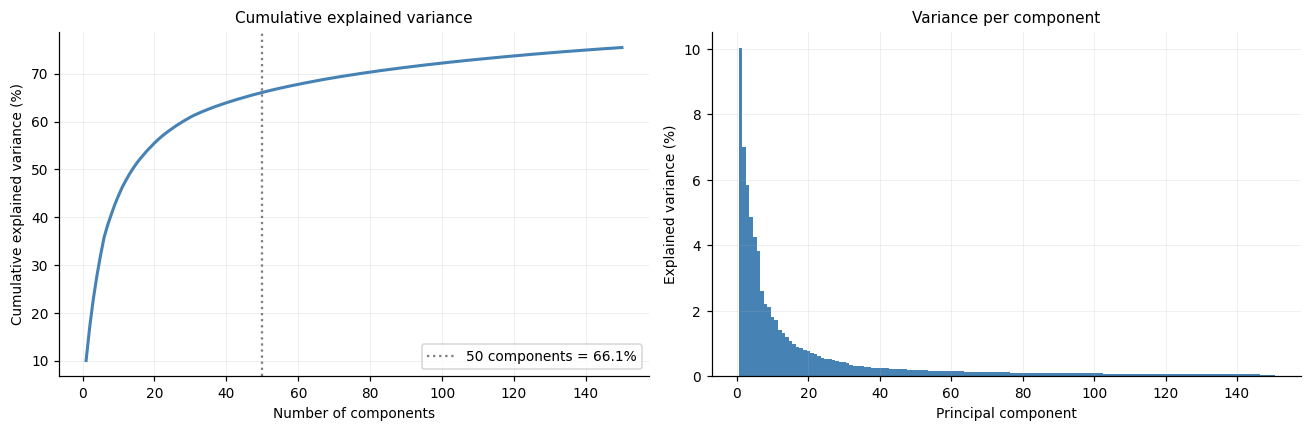

In [5]:
idx = np.arange(len(y))
tr, te = train_test_split(idx, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
y_train, y_test = y[tr], y[te]
X_train, X_test = X[tr], X[te]
C_train, C_test = C.iloc[tr], C.iloc[te]

N_COMPONENTS = 150
tx = pr.tx_transformer(N_COMPONENTS).fit(X_train, y_train)
Z_train, Z_test = tx.transform(X_train), tx.transform(X_test)
pca, vt, l1 = tx.named_steps["pca"], tx.named_steps["var"], tx.named_steps["l1"]
genes_vt = gene_names[vt.get_support()]
PC_train = tx[:-1].transform(X_train)        # all 150 standardized component scores
cumvar = np.cumsum(pca.explained_variance_ratio_) * 100

print(f"Train {len(tr):,} | test {len(te):,} | high risk {y_train.mean() * 100:.1f}% and {y_test.mean() * 100:.1f}%")
print(f"Genes after variance filter: {len(genes_vt):,}")
print(f"Components kept by L1 selection: {Z_train.shape[1]} of {N_COMPONENTS}")
for k in (10, 50, 100, N_COMPONENTS):
    print(f"  first {k:>3} components explain {cumvar[k - 1]:5.1f}% of variance")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(range(1, N_COMPONENTS + 1), cumvar, color="steelblue", lw=2)
axes[0].axvline(50, color="grey", ls=":", label=f"50 components = {cumvar[49]:.1f}%")
axes[0].set_xlabel("Number of components"); axes[0].set_ylabel("Cumulative explained variance (%)")
axes[0].set_title("Cumulative explained variance"); axes[0].legend()
axes[1].bar(range(1, N_COMPONENTS + 1), pca.explained_variance_ratio_ * 100, color="steelblue", width=1.0)
axes[1].set_xlabel("Principal component"); axes[1].set_ylabel("Explained variance (%)")
axes[1].set_title("Variance per component")
plt.tight_layout(); save_fig("figure2_pca_diagnostics"); plt.show()

## 5. Analytical workflow (Figure 1)

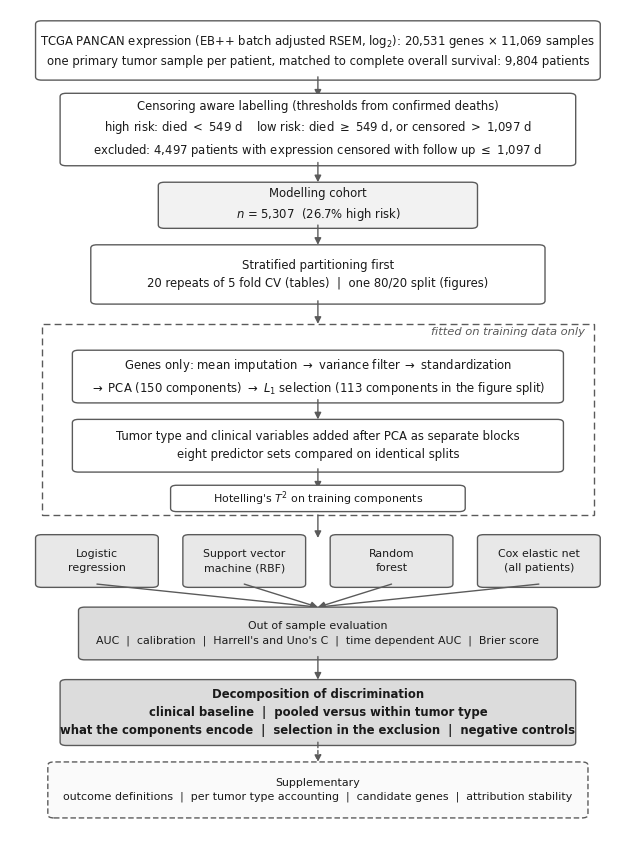

In [6]:
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch, Rectangle

INK, RULE = "#1a1a1a", "#5a5a5a"
FILL = {"data": "#f2f2f2", "step": "#ffffff", "model": "#e8e8e8", "result": "#dcdcdc", "supp": "#fafafa"}
fig, ax = plt.subplots(figsize=(7.2, 9.8))
ax.set_xlim(0, 10); ax.set_ylim(0, 25.2); ax.axis("off"); ax.grid(False)


def box(x, y0, w, h, text, kind="step", dashed=False, fs=7.6, weight="normal"):
    ax.add_patch(FancyBboxPatch((x, y0), w, h, boxstyle="round,pad=0.10", linewidth=0.9,
                                edgecolor=RULE, facecolor=FILL[kind],
                                linestyle=(0, (4, 2)) if dashed else "-"))
    ax.text(x + w / 2, y0 + h / 2, text, ha="center", va="center", fontsize=fs, color=INK,
            linespacing=1.5, fontweight=weight)


def arrow(x1, y1, x2, y2, dashed=False):
    ax.add_patch(FancyArrowPatch((x1, y1), (x2, y2), arrowstyle="-|>", mutation_scale=9,
                                 linewidth=0.9, color=RULE, shrinkA=0, shrinkB=0,
                                 linestyle=(0, (4, 2)) if dashed else "-"))


n_patients = Xdf.shape[0]
box(0.5, 23.2, 9.0, 1.6,
    "TCGA PANCAN expression (EB++ batch adjusted RSEM, log$_2$): 20,531 genes $\\times$ 11,069 samples\n"
    f"one primary tumor sample per patient, matched to complete overall survival: {n_patients:,} patients")
arrow(5, 23.2, 5, 22.6)
box(0.9, 20.6, 8.2, 2.0,
    "Censoring aware labelling (thresholds from confirmed deaths)\n"
    f"high risk: died $<$ {median_t:.0f} d    low risk: died $\\geq$ {median_t:.0f} d, or censored $>$ {p75_t:,.0f} d\n"
    f"excluded: {int((~lab).sum()):,} patients with expression censored with follow up $\\leq$ {p75_t:,.0f} d")
arrow(5, 20.6, 5, 20.0)
box(2.5, 18.7, 5.0, 1.2, f"Modelling cohort\n$n$ = {len(y):,}  ({y.mean() * 100:.1f}% high risk)", "data")
arrow(5, 18.7, 5, 18.1)
box(1.4, 16.4, 7.2, 1.6, "Stratified partitioning first\n"
    "20 repeats of 5 fold CV (tables)  |  one 80/20 split (figures)", "step")
arrow(5, 16.4, 5, 15.7)
ax.add_patch(Rectangle((0.5, 9.9), 9.0, 5.8, facecolor="none", edgecolor=RULE, linewidth=0.9,
                       linestyle=(0, (5, 3)), zorder=0))
ax.text(9.35, 15.45, "fitted on training data only", ha="right", va="center", fontsize=7.5,
        style="italic", color=RULE)
box(1.1, 13.4, 7.8, 1.4, "Genes only: mean imputation $\\rightarrow$ variance filter $\\rightarrow$ standardization\n"
    f"$\\rightarrow$ PCA (150 components) $\\rightarrow$ $L_1$ selection ({Z_train.shape[1]} components in the figure split)")
arrow(5, 13.4, 5, 12.8)
box(1.1, 11.3, 7.8, 1.4, "Tumor type and clinical variables added after PCA as separate blocks\n"
    "eight predictor sets compared on identical splits")
arrow(5, 11.3, 5, 10.7)
box(2.7, 10.1, 4.6, 0.6, "Hotelling's $T^2$ on training components", fs=7.2)
arrow(5, 9.9, 5, 9.2)
for x0, lbl in [(0.5, "Logistic\nregression"), (2.9, "Support vector\nmachine (RBF)"),
                (5.3, "Random\nforest"), (7.7, "Cox elastic net\n(all patients)")]:
    box(x0, 7.8, 1.8, 1.4, lbl, "model", fs=7.2)
    arrow(x0 + 0.9, 7.8, 5, 7.1)
box(1.2, 5.6, 7.6, 1.4, "Out of sample evaluation\nAUC  |  calibration  |  Harrell's and Uno's C  |  time dependent AUC  |  Brier score",
    "result", fs=7.2)
arrow(5, 5.6, 5, 4.9)
box(0.9, 3.0, 8.2, 1.8, "Decomposition of discrimination\nclinical baseline  |  pooled versus within tumor type\n"
    "what the components encode  |  selection in the exclusion  |  negative controls", "result", weight="bold")
arrow(5, 3.0, 5, 2.4, dashed=True)
box(0.7, 0.8, 8.6, 1.5, "Supplementary\noutcome definitions  |  per tumor type accounting  |  candidate genes  |  attribution stability",
    "supp", dashed=True, fs=7.2)
save_fig("figure1_workflow"); plt.show()

## 6. Multivariate group separation

Hotelling's $T^2$ on all 150 standardized training components (genes only). With two groups the
MANOVA statistics are equivalent; Pillai's trace, Mahalanobis $D^2$ and Cohen's $f^2$ are reported as
effect sizes because significance is almost guaranteed at this sample size.

In [7]:
def hotelling_t2(X1, X2):
    # two sample Hotelling T2 with closed form Pillai trace and effect sizes
    n1, n2, p = len(X1), len(X2), X1.shape[1]
    N = n1 + n2
    d = X1.mean(0) - X2.mean(0)
    S = ((n1 - 1) * np.cov(X1, rowvar=False) + (n2 - 1) * np.cov(X2, rowvar=False)) / (N - 2)
    D2 = float(d @ np.linalg.pinv(S) @ d)
    T2 = n1 * n2 / N * D2
    F = T2 * (N - p - 1) / (p * (N - 2))
    pillai = T2 / (T2 + N - 2)
    return dict(T2=T2, F=F, df1=p, df2=N - p - 1, p_value=float(st.f.sf(F, p, N - p - 1)),
                pillai=pillai, mahalanobis_D2=D2, cohens_f2=pillai / (1 - pillai))


t2 = hotelling_t2(PC_train[y_train == 1], PC_train[y_train == 0])
for k, v in t2.items():
    print(f"  {k:<16} {v:.4g}")

  T2               1783
  F                11.47
  df1              150
  df2              4094
  p_value          1.24e-213
  pillai           0.2959
  mahalanobis_D2   2.148
  cohens_f2        0.4203


## 7. Discriminant projection (supplementary)

A one dimensional supervised projection of the selected components, shown as a visual check on
separability.

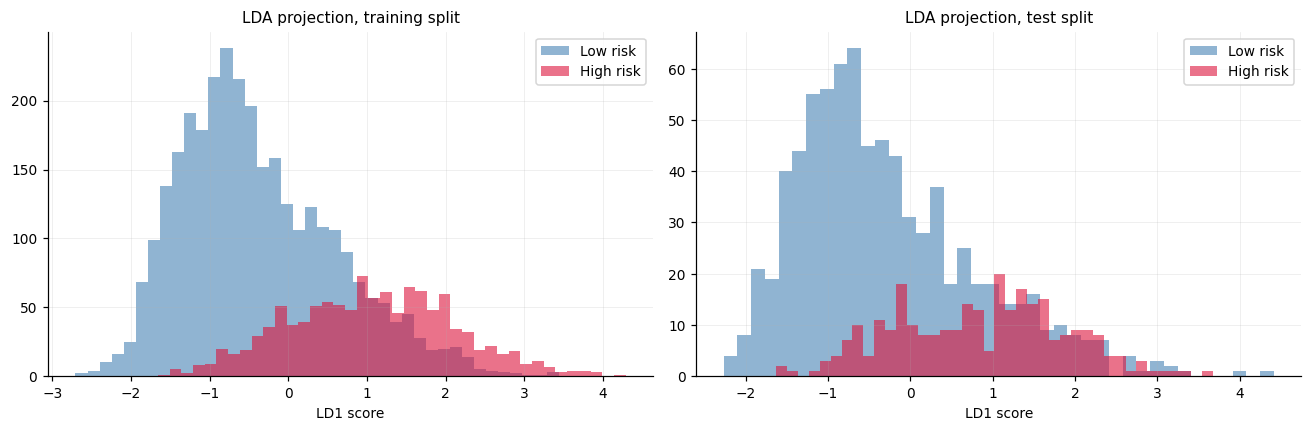

LDA test AUC: 0.7846


In [8]:
lda = LinearDiscriminantAnalysis(n_components=1).fit(Z_train, y_train)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, Zp, yy, title in [(axes[0], lda.transform(Z_train), y_train, "Training split"),
                          (axes[1], lda.transform(Z_test), y_test, "Test split")]:
    for g, lbl, col in [(0, "Low risk", "steelblue"), (1, "High risk", "crimson")]:
        ax.hist(Zp[yy == g, 0], bins=40, alpha=0.6, label=lbl, color=col)
    ax.set_title(f"LDA projection, {title.lower()}"); ax.set_xlabel("LD1 score"); ax.legend()
plt.tight_layout(); save_fig("figureS_lda_projection"); plt.show()
print(f"LDA test AUC: {roc_auc_score(y_test, lda.predict_proba(Z_test)[:, 1]):.4f}")

## 8. Predictor sets and classifiers

Each predictor set is fitted once with L2 logistic regression. The support vector machine and the
random forest are fitted once to the transcriptome only and the transcriptome plus tumor type sets.
The same fitted objects supply the classification reports, confusion matrices, ROC curves,
calibration curves and attribution analyses.

In [9]:
def design(cols, with_tx):
    # stack the transcriptome block and the clinical block encoded on training data
    A, B = [], []
    if with_tx:
        A.append(Z_train); B.append(Z_test)
    if cols:
        enc = pr.ClinEncoder(cols).fit(C_train)
        A.append(enc.transform(C_train)); B.append(enc.transform(C_test))
    return np.hstack(A), np.hstack(B)


DES = {k: design(cols, t is not None) for k, (t, cols) in pr.FEATURE_SETS.items()}
PRED, MODELS = {}, {}
for k, (A, B) in DES.items():
    MODELS[k] = pr.clf().fit(A, y_train)
    PRED[k] = MODELS[k].predict_proba(B)[:, 1]

CLASSIFIERS = {}
for setname in ("transcriptome_only", "transcriptome_plus_tumor_type"):
    A, B = DES[setname]
    CLASSIFIERS[(setname, "Logistic regression")] = MODELS[setname]
    for tag, est in pr.other_classifiers().items():
        name = {"svm_rbf": "SVM (RBF, Platt)", "random_forest": "Random forest"}[tag]
        CLASSIFIERS[(setname, name)] = clone(est).fit(A, y_train)

PROB = {key: m.predict_proba(DES[key[0]][1])[:, 1] for key, m in CLASSIFIERS.items()}
rows = [dict(predictor_set=s, model=m, n_features=DES[s][0].shape[1], test_auc=roc_auc_score(y_test, p))
        for (s, m), p in PROB.items()]
single = pd.DataFrame(rows)
single.to_csv(TAB_DIR / "tableS1_single_split.csv", index=False)
print(single.round(4).to_string(index=False))

for (s, m), p in PROB.items():
    if s == "transcriptome_only":
        print(f"\n{m}, transcriptome only")
        print(classification_report(y_test, (p >= 0.5).astype(int), target_names=["Low risk", "High risk"]))

                predictor_set               model  n_features  test_auc
           transcriptome_only Logistic regression         113    0.7892
           transcriptome_only    SVM (RBF, Platt)         113    0.7931
           transcriptome_only       Random forest         113    0.7854
transcriptome_plus_tumor_type Logistic regression         146    0.7892
transcriptome_plus_tumor_type    SVM (RBF, Platt)         146    0.7933
transcriptome_plus_tumor_type       Random forest         146    0.7865

Logistic regression, transcriptome only
              precision    recall  f1-score   support

    Low risk       0.87      0.72      0.78       779
   High risk       0.47      0.70      0.56       283

    accuracy                           0.71      1062
   macro avg       0.67      0.71      0.67      1062
weighted avg       0.76      0.71      0.72      1062


SVM (RBF, Platt), transcriptome only
              precision    recall  f1-score   support

    Low risk       0.82      0.88  

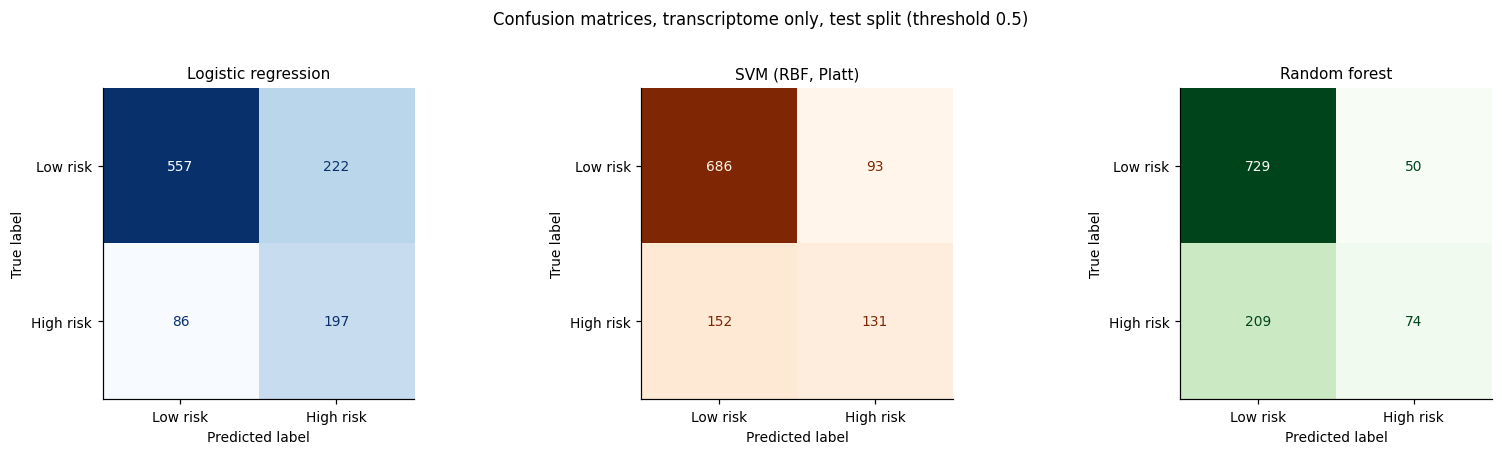

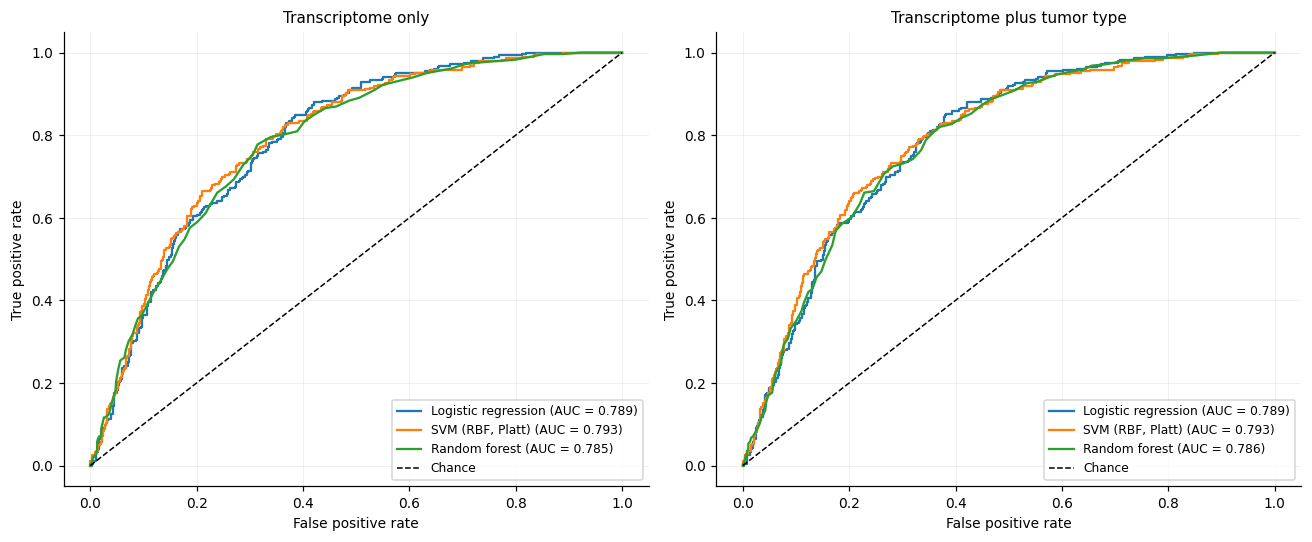

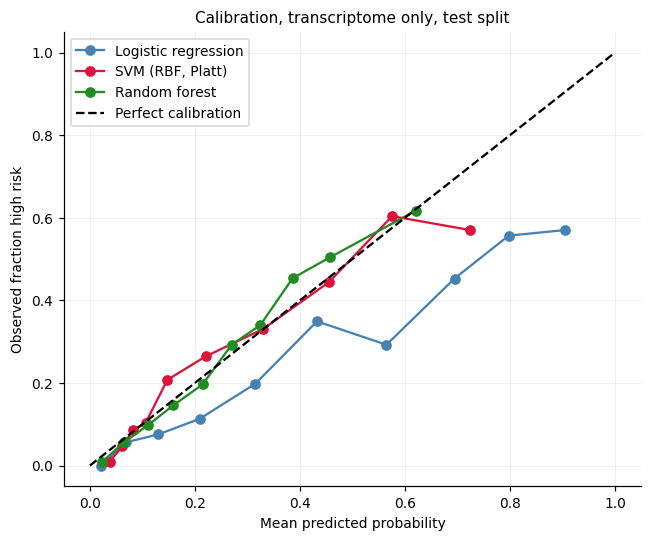

Balanced class weights shift predicted probabilities upward, so logistic regression is expected to
over predict risk; calibration over repeated splits is reported by pancancer_revision.py.


In [10]:
names = ["Logistic regression", "SVM (RBF, Platt)", "Random forest"]
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, m, cmap in zip(axes, names, ["Blues", "Oranges", "Greens"]):
    p = PROB[("transcriptome_only", m)]
    ConfusionMatrixDisplay(confusion_matrix(y_test, (p >= 0.5).astype(int)),
                           display_labels=["Low risk", "High risk"]).plot(ax=ax, cmap=cmap, colorbar=False)
    ax.set_title(m); ax.grid(False)
plt.suptitle("Confusion matrices, transcriptome only, test split (threshold 0.5)", y=1.02)
plt.tight_layout(); save_fig("figureS_confusion_matrices"); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, s, title in [(axes[0], "transcriptome_only", "Transcriptome only"),
                     (axes[1], "transcriptome_plus_tumor_type", "Transcriptome plus tumor type")]:
    for m in names:
        p = PROB[(s, m)]
        fpr, tpr, _ = roc_curve(y_test, p)
        ax.plot(fpr, tpr, label=f"{m} (AUC = {roc_auc_score(y_test, p):.3f})")
    ax.plot([0, 1], [0, 1], "k--", lw=1, label="Chance")
    ax.set_xlabel("False positive rate"); ax.set_ylabel("True positive rate"); ax.set_title(title)
    ax.legend(loc="lower right", fontsize=8)
plt.tight_layout(); save_fig("figure3_roc_curves"); plt.show()

fig, ax = plt.subplots(figsize=(6, 5))
for m, col in zip(names, ["steelblue", "crimson", "forestgreen"]):
    fp, mp = calibration_curve(y_test, PROB[("transcriptome_only", m)], n_bins=10, strategy="quantile")
    ax.plot(mp, fp, marker="o", label=m, color=col)
ax.plot([0, 1], [0, 1], "k--", label="Perfect calibration")
ax.set_xlabel("Mean predicted probability"); ax.set_ylabel("Observed fraction high risk")
ax.set_title("Calibration, transcriptome only, test split"); ax.legend()
plt.tight_layout(); save_fig("figureS_calibration"); plt.show()
print("Balanced class weights shift predicted probabilities upward, so logistic regression is expected to")
print("over predict risk; calibration over repeated splits is reported by pancancer_revision.py.")

## 9. Cross validation within the training split

Every step of the representation is refitted inside each fold, so no fold is scored with components or
selections that saw its own patients. The main repeated cross validation (20 by 5 folds on the whole
cohort) is in `pancancer_revision.py`.

In [11]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_rows = []
for f, (a, b) in enumerate(cv.split(X_train, y_train)):
    t = pr.tx_transformer(N_COMPONENTS).fit(X_train[a], y_train[a])
    Za, Zb = t.transform(X_train[a]), t.transform(X_train[b])
    ests = {"Logistic regression": pr.clf(), **{{"svm_rbf": "SVM (RBF, Platt)", "random_forest": "Random forest"}[k]: v
                                                for k, v in pr.other_classifiers().items()}}
    for m, est in ests.items():
        cv_rows.append(dict(fold=f + 1, model=m,
                            auc=roc_auc_score(y_train[b], clone(est).fit(Za, y_train[a]).predict_proba(Zb)[:, 1])))
cv_res = pd.DataFrame(cv_rows).pivot(index="model", columns="fold", values="auc")
cv_res["mean"], cv_res["sd"] = cv_res.mean(1), cv_res.iloc[:, :5].std(1, ddof=1)
print("Five fold CV AUC within the training split, transcriptome only, all steps refitted per fold")
print(cv_res.round(4).to_string())

Five fold CV AUC within the training split, transcriptome only, all steps refitted per fold
fold                      1       2       3       4       5    mean      sd
model                                                                      
Logistic regression  0.8010  0.8005  0.8363  0.8212  0.8019  0.8122  0.0161
Random forest        0.7917  0.8090  0.8164  0.8118  0.8020  0.8062  0.0096
SVM (RBF, Platt)     0.7978  0.8094  0.8278  0.8222  0.7945  0.8103  0.0146


## 10. Censoring aware Cox model on all patients

The Cox model uses every patient with overall survival data, including the censored patients excluded
from the binary analysis. The transcriptome block is unsupervised PCA (no L1 step), so no part of the
survival model uses the binary labels. Partition: 80/20 of all patients, stratified by event status.
Repeated splits, calibration and proportional hazards tests are in `pancancer_revision.py`.

In [12]:
from lifelines import CoxPHFitter
from sklearn.decomposition import PCA
from sklearn.feature_selection import VarianceThreshold
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sksurv.metrics import concordance_index_censored, concordance_index_ipcw
from sksurv.util import Surv

T_all, E_all = clin["OS.time"].values.astype(float), clin["OS"].values.astype(int)
X_full = Xdf.values
s_tr, s_te = train_test_split(np.arange(len(T_all)), test_size=0.2, stratify=E_all, random_state=RANDOM_STATE)
pca_all = Pipeline([("imp", SimpleImputer()), ("var", VarianceThreshold(0.5)), ("sc", StandardScaler()),
                    ("pca", PCA(N_COMPONENTS, random_state=RANDOM_STATE, svd_solver="randomized")),
                    ("sc_pc", StandardScaler())]).fit(X_full[s_tr])
P_tr, P_te = pca_all.transform(X_full[s_tr]), pca_all.transform(X_full[s_te])
cox_rows = []
for name, use_pc, cols in [("Clinical", False, ["age", "sex", "stage", "type"]),
                           ("Transcriptome", True, []),
                           ("Combined", True, ["age", "sex", "stage", "type"])]:
    A, B = ([P_tr], [P_te]) if use_pc else ([], [])
    if cols:
        enc = pr.ClinEncoder(cols).fit(C_all.iloc[s_tr])
        A.append(enc.transform(C_all.iloc[s_tr])); B.append(enc.transform(C_all.iloc[s_te]))
    A, B = np.hstack(A), np.hstack(B)
    keep = A.std(0) > 0
    fc = [f"f{i}" for i in range(int(keep.sum()))]
    dtr = pd.DataFrame(A[:, keep], columns=fc); dtr["T"], dtr["E"] = T_all[s_tr], E_all[s_tr]
    cph = CoxPHFitter(penalizer=0.05, l1_ratio=0.5).fit(dtr, "T", "E")
    risk = cph.predict_partial_hazard(pd.DataFrame(B[:, keep], columns=fc)).values.ravel()
    Tt, Et = T_all[s_te], E_all[s_te].astype(bool)
    inr = Tt < T_all[s_tr].max()
    uno = concordance_index_ipcw(Surv.from_arrays(E_all[s_tr].astype(bool), T_all[s_tr]),
                                 Surv.from_arrays(Et[inr], Tt[inr]), risk[inr], tau=1825)[0]
    ty = types_all[s_te]
    wc = [(concordance_index_censored(Et[ty == t], Tt[ty == t], risk[ty == t])[0], (ty == t).sum())
          for t in np.unique(ty) if Et[ty == t].sum() >= 5]
    cox_rows.append(dict(model=name, n_train=len(s_tr), n_test=len(s_te),
                         harrell_c=concordance_index_censored(Et, Tt, risk)[0], uno_c_5y=uno,
                         within_type_c=np.average([c for c, _ in wc], weights=[n for _, n in wc])))
cox_single = pd.DataFrame(cox_rows)
cox_single.to_csv(TAB_DIR / "cox_single_split_all_patients.csv", index=False)
print(f"Patients in the Cox analysis: {len(T_all):,} ({int(E_all.sum()):,} deaths)")
print(cox_single.round(4).to_string(index=False))

Patients in the Cox analysis: 9,804 (2,801 deaths)
        model  n_train  n_test  harrell_c  uno_c_5y  within_type_c
     Clinical     7843    1961     0.7632    0.7493         0.6636
Transcriptome     7843    1961     0.7440    0.7248         0.6243
     Combined     7843    1961     0.7774    0.7632         0.6877


## 11. What the discrimination is made of

### 11.1 Clinical baseline

In [13]:
LABELS = {"tumor_type_only": "Tumor type alone", "age_only": "Age at diagnosis alone",
          "site_only": "Contributing site alone", "clinical_only": "Tumor type + age + sex + stage",
          "clinical_plus_year": "... + year of diagnosis", "transcriptome_only": "Transcriptome only",
          "transcriptome_plus_tumor_type": "Transcriptome + tumor type", "combined": "Transcriptome + clinical"}
base = pd.DataFrame([dict(predictor_set=LABELS[k], n_features=DES[k][0].shape[1],
                          test_auc=roc_auc_score(y_test, PRED[k])) for k in LABELS])
base.to_csv(TAB_DIR / "table3_single_split.csv", index=False)
print(base.round(4).to_string(index=False))
print("\nStage is grouped I to IV from AJCC pathologic stage (clinical stage when missing); sub stages such as")
print("IIA or IVB are collapsed to their main group.")
print(pd.Series(C["stage"]).value_counts().to_string())

                 predictor_set  n_features  test_auc
              Tumor type alone          33    0.7473
        Age at diagnosis alone           1    0.6244
       Contributing site alone         477    0.7608
Tumor type + age + sex + stage          41    0.7952
       ... + year of diagnosis          42    0.8029
            Transcriptome only         113    0.7892
    Transcriptome + tumor type         146    0.7892
      Transcriptome + clinical         154    0.8147

Stage is grouped I to IV from AJCC pathologic stage (clinical stage when missing); sub stages such as
IIA or IVB are collapsed to their main group.
stage
I      1275
III    1181
II     1146
NA     1018
IV      687


### 11.2 Incremental value of the transcriptome: paired bootstrap and DeLong test

In [14]:
rng = np.random.default_rng(RANDOM_STATE)
keys = ["clinical_only", "transcriptome_only", "combined"]
boot = {k: [] for k in keys}
for _ in range(2000):
    q = rng.integers(0, len(y_test), len(y_test))
    if len(np.unique(y_test[q])) < 2:
        continue
    for k in keys:
        boot[k].append(roc_auc_score(y_test[q], PRED[k][q]))
rows = []
for a, b in [("transcriptome_only", "clinical_only"), ("combined", "clinical_only"),
             ("combined", "transcriptome_only")]:
    d = np.array(boot[a]) - np.array(boot[b])
    a1, a2, diff, z, p = pr.delong(y_test, PRED[a], PRED[b])
    rows.append(dict(comparison=f"{LABELS[a]} minus {LABELS[b]}", delta_auc=diff,
                     boot_lo=np.percentile(d, 2.5), boot_hi=np.percentile(d, 97.5), delong_p=p))
inc = pd.DataFrame(rows)
inc.to_csv(TAB_DIR / "table4_single_split.csv", index=False)
print(inc.round(4).to_string(index=False))

                                                   comparison  delta_auc  boot_lo  boot_hi  delong_p
      Transcriptome only minus Tumor type + age + sex + stage    -0.0060  -0.0294   0.0165    0.6114
Transcriptome + clinical minus Tumor type + age + sex + stage     0.0195   0.0031   0.0354    0.0164
            Transcriptome + clinical minus Transcriptome only     0.0255   0.0129   0.0379    0.0001


### 11.3 What the transcriptome only components encode

The components come from gene expression alone, so recovery of tumor type here cannot come from
the tumor type indicators.

In [15]:
pr.encoding_recovery(Z_train, Z_test, C_train, C_test, str(TAB_DIR))
enc_rec = pd.read_csv(TAB_DIR / "R1_1_encoding_recovery.csv")
print(enc_rec.round(3).to_string(index=False))

           target   metric  value  chance  n_classes  n_test
       tumor type accuracy  0.941   0.115         33    1062
              sex      AUC  0.968   0.500          2    1062
contributing site accuracy  0.564   0.054         58     557


### 11.4 Pooled versus within tumor type, with accounting for every tumor type

A tumor type enters the within type average when the test split holds at least 20 of its patients
and at least 3 in each risk group. The table lists all tumor types with the reason for exclusion,
bootstrap intervals for each within type AUC, and the pooled AUC recomputed on the patients of the
included types only.

In [16]:
acc = pr.per_type_accounting(y, types_all, types, te, PRED, str(TAB_DIR))
pd.set_option("display.width", 250)
cols = ["type", "n_test", "n_test_high", "n_test_low", "included", "reason_excluded",
        "auc_transcriptome_only", "auc_transcriptome_only_lo", "auc_transcriptome_only_hi",
        "auc_clinical_only", "auc_combined"]
print(acc[cols].round(3).to_string(index=False))
pooled_inc = pd.read_csv(TAB_DIR / "R1_4_pooled_auc_included_types.csv")
print("\n" + pooled_inc.round(4).to_string(index=False))

SUMMARY = {}
for k in ("clinical_only", "transcriptome_only", "combined"):
    wt, per = pr.within_type_auc(y_test, PRED[k], types[te], min_n=20)
    SUMMARY[k] = (roc_auc_score(y_test, PRED[k]), wt)
PER = acc[acc.included].copy()
print(f"\nIncluded tumor types: {len(PER)} of {len(acc)}")
for k, (a, b) in SUMMARY.items():
    print(f"  {LABELS[k]:<32} pooled {a:.4f}   within type {b:.4f}   gap {a - b:+.4f}")
print(f"Transcriptome beats the clinical model within type in "
      f"{int((PER.auc_transcriptome_only > PER.auc_clinical_only).sum())} of {len(PER)} types")

type  n_test  n_test_high  n_test_low  included                              reason_excluded  auc_transcriptome_only  auc_transcriptome_only_lo  auc_transcriptome_only_hi  auc_clinical_only  auc_combined
 ACC      11            0          11     False                  fewer than 20 test patients                     NaN                        NaN                        NaN                NaN           NaN
BLCA      50           22          28      True                                                                0.589                      0.424                      0.737              0.749         0.729
BRCA     122            9         113      True                                                                0.741                      0.559                      0.899              0.820         0.858
CESC      35           10          25      True                                                                0.660                      0.460                      0.836              

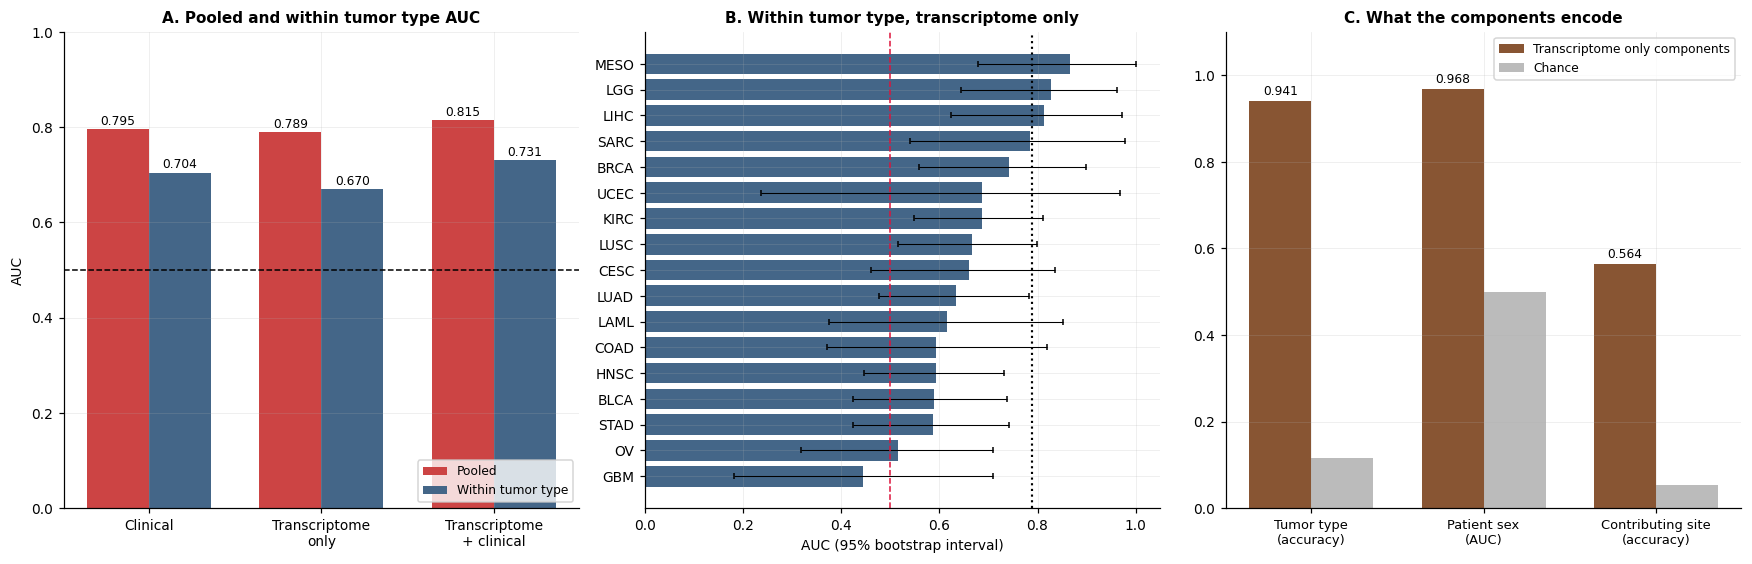

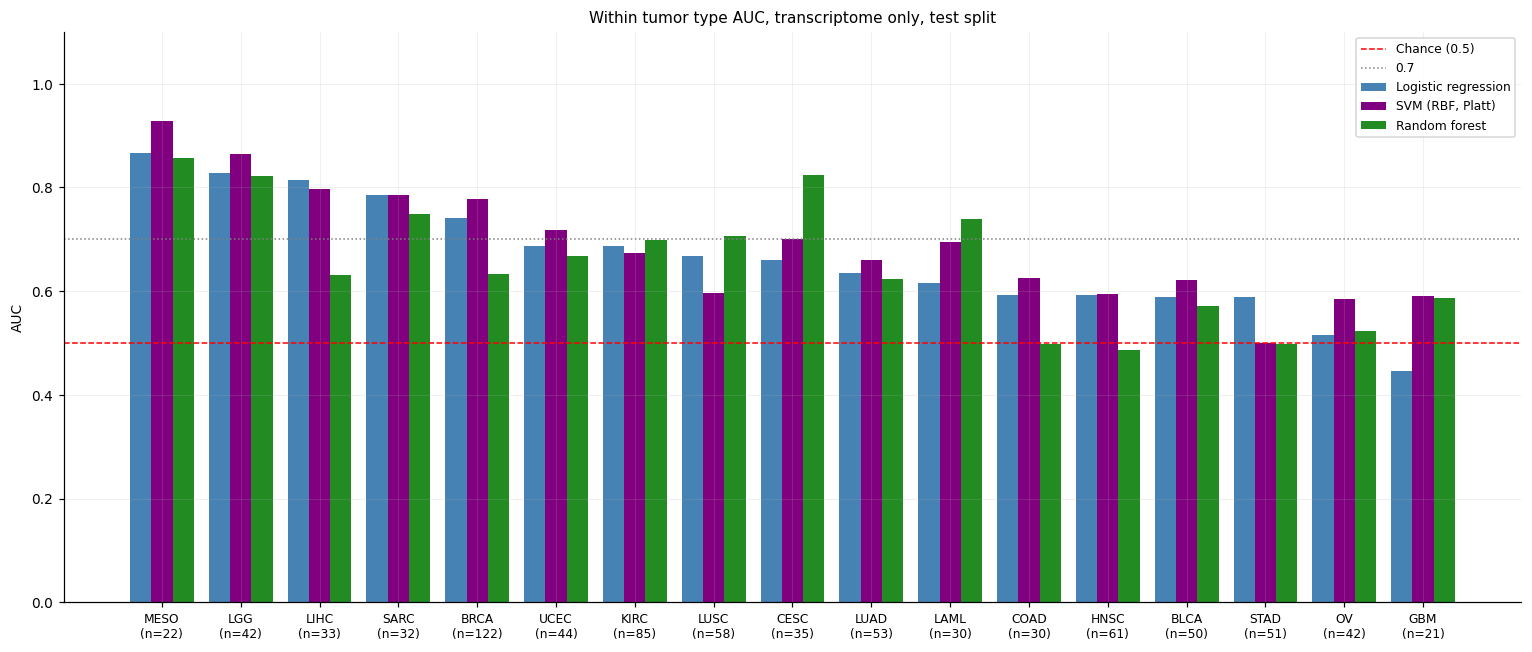

In [17]:
fig, ax = plt.subplots(1, 3, figsize=(16, 5.2))
kk = ["clinical_only", "transcriptome_only", "combined"]
xx, w = np.arange(3), 0.36
pool, within = [SUMMARY[k][0] for k in kk], [SUMMARY[k][1] for k in kk]
ax[0].bar(xx - w / 2, pool, w, color="#c44", label="Pooled")
ax[0].bar(xx + w / 2, within, w, color="#468", label="Within tumor type")
for i, (a, b) in enumerate(zip(pool, within)):
    ax[0].text(i - w / 2, a + 0.01, f"{a:.3f}", ha="center", fontsize=8)
    ax[0].text(i + w / 2, b + 0.01, f"{b:.3f}", ha="center", fontsize=8)
ax[0].axhline(0.5, color="k", ls="--", lw=1)
ax[0].set_xticks(xx); ax[0].set_xticklabels(["Clinical", "Transcriptome\nonly", "Transcriptome\n+ clinical"])
ax[0].set_ylim(0, 1); ax[0].set_ylabel("AUC"); ax[0].legend(fontsize=8, loc="lower right")
ax[0].set_title("A. Pooled and within tumor type AUC", fontweight="bold")

S = PER.sort_values("auc_transcriptome_only")
err = np.vstack([S.auc_transcriptome_only - S.auc_transcriptome_only_lo,
                 S.auc_transcriptome_only_hi - S.auc_transcriptome_only])
ax[1].barh(S.type, S.auc_transcriptome_only, xerr=err, color="#468", error_kw=dict(lw=0.7, capsize=2))
ax[1].axvline(0.5, color="crimson", ls="--", lw=1)
ax[1].axvline(SUMMARY["transcriptome_only"][0], color="k", ls=":", lw=1.4)
ax[1].set_xlim(0, 1.05); ax[1].set_xlabel("AUC (95% bootstrap interval)")
ax[1].set_title("B. Within tumor type, transcriptome only", fontweight="bold")

ER = enc_rec.set_index("target")
lbl = ["Tumor type\n(accuracy)", "Patient sex\n(AUC)", "Contributing site\n(accuracy)"]
val = ER.loc[["tumor type", "sex", "contributing site"], "value"].values
chn = ER.loc[["tumor type", "sex", "contributing site"], "chance"].values
ax[2].bar(np.arange(3) - 0.18, val, 0.36, color="#853", label="Transcriptome only components")
ax[2].bar(np.arange(3) + 0.18, chn, 0.36, color="#bbb", label="Chance")
for i, v in enumerate(val):
    ax[2].text(i - 0.18, v + 0.015, f"{v:.3f}", ha="center", fontsize=8)
ax[2].set_xticks(range(3)); ax[2].set_xticklabels(lbl, fontsize=8.5); ax[2].set_ylim(0, 1.1)
ax[2].legend(fontsize=8); ax[2].set_title("C. What the components encode", fontweight="bold")
plt.tight_layout(); save_fig("figure4_pooled_within_encoding"); plt.show()

fig, ax = plt.subplots(figsize=(14, 6))
S = PER.sort_values("auc_transcriptome_only", ascending=False)
pos = np.arange(len(S))
tmask = np.isin(types[te], S.type.values)
for j, (m, col) in enumerate(zip(names, ["steelblue", "purple", "forestgreen"])):
    vals = [roc_auc_score(y_test[types[te] == t], PROB[("transcriptome_only", m)][types[te] == t]) for t in S.type]
    ax.bar(pos + (j - 1) * 0.27, vals, 0.27, label=m, color=col)
ax.axhline(0.5, color="red", ls="--", lw=1, label="Chance (0.5)")
ax.axhline(0.7, color="grey", ls=":", lw=1, label="0.7")
ax.set_xticks(pos); ax.set_xticklabels([f"{t}\n(n={n})" for t, n in zip(S.type, S.n_test)], fontsize=8)
ax.set_ylim(0, 1.1); ax.set_ylabel("AUC"); ax.legend(loc="upper right", fontsize=8)
ax.set_title("Within tumor type AUC, transcriptome only, test split")
plt.tight_layout(); save_fig("figure5_per_type_auc"); plt.show()

### 11.5 Selection in the censoring based exclusion

The labelling rule is applied to the full patient level clinical table, so the comparison concerns
the exclusion rule itself and not the availability of an expression profile.

                                                          item    excluded    retained             p
                                                             n 4719.000000 6296.000000           NaN
                                      median year of diagnosis 2011.000000 2007.000000  0.000000e+00
                                                    median age   60.000000   61.000000  7.068947e-04
                                       median follow up (days)  528.000000 1220.000000  0.000000e+00
                                 stage I percent (known stage)   34.645248   28.276574  1.055945e-39
                                stage II percent (known stage)   32.396252   25.614035  1.055945e-39
                               stage III percent (known stage)   24.899598   30.381837  1.055945e-39
                                stage IV percent (known stage)    8.058902   15.727554  1.055945e-39
                                                female percent   53.401144   51.222999  2.4

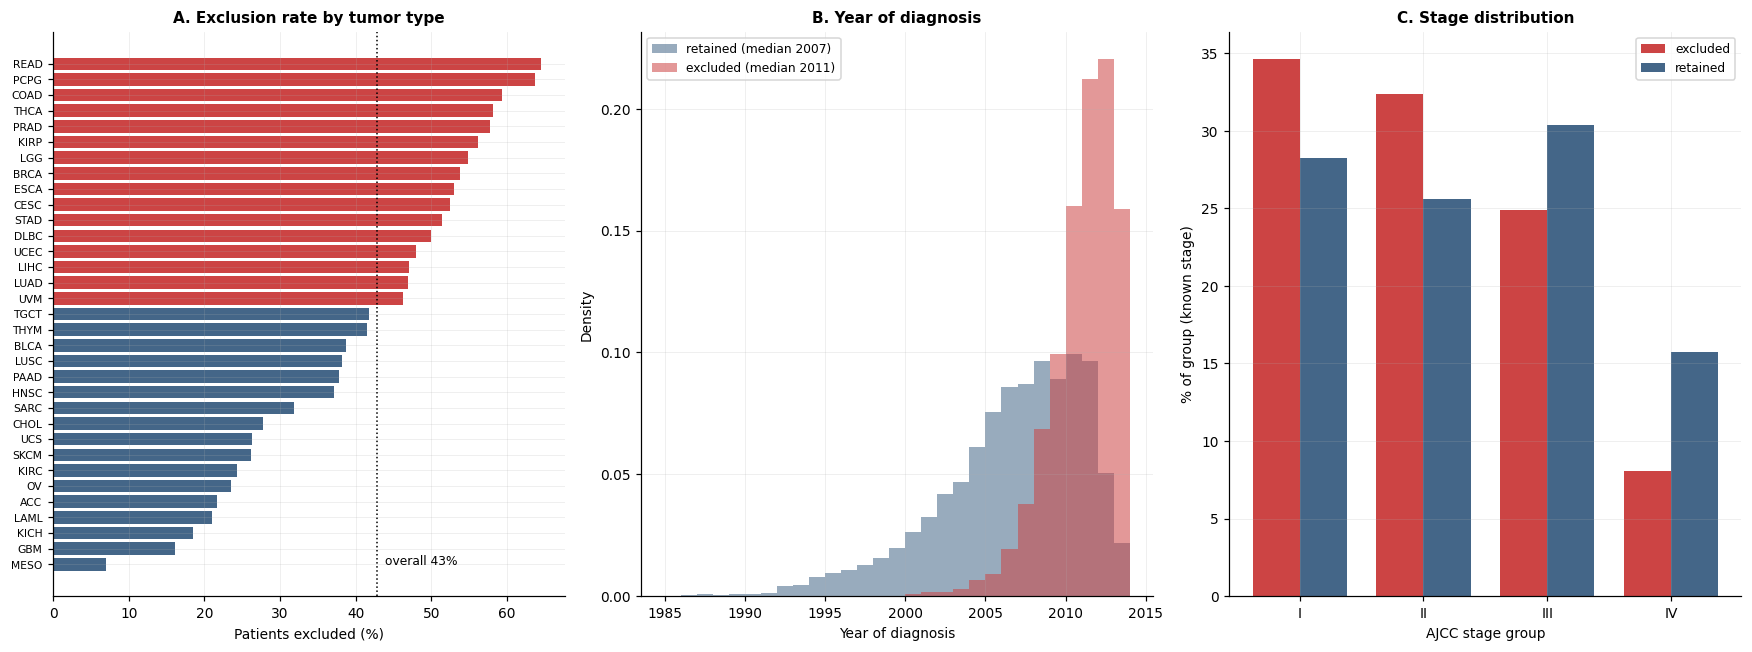

In [18]:
D = pr.exclusion_characteristics(clin_full, thr, str(TAB_DIR))
print(pd.read_csv(TAB_DIR / "R2_3_retained_vs_excluded.csv").to_string(index=False))

bt = pd.read_csv(TAB_DIR / "R2_3_exclusion_by_type.csv", index_col=0).sort_values("pct_excluded")
overall = 100 * (D.group == "excluded").mean()
fig, ax = plt.subplots(1, 3, figsize=(16, 6))
ax[0].barh(bt.index, bt.pct_excluded, color=np.where(bt.pct_excluded > overall, "#c44", "#468"))
ax[0].axvline(overall, color="k", ls=":", lw=1); ax[0].text(overall + 1, 0, f"overall {overall:.0f}%", fontsize=8)
ax[0].set_xlabel("Patients excluded (%)"); ax[0].set_title("A. Exclusion rate by tumor type", fontweight="bold")
ax[0].tick_params(axis="y", labelsize=7)
bins = np.arange(1985, 2015)
for g, col in [("retained", "#468"), ("excluded", "#c44")]:
    v = D.loc[D.group == g, "initial_pathologic_dx_year"].dropna()
    ax[1].hist(v, bins=bins, density=True, alpha=0.55, color=col, label=f"{g} (median {v.median():.0f})")
ax[1].set_xlabel("Year of diagnosis"); ax[1].set_ylabel("Density"); ax[1].legend(fontsize=8)
ax[1].set_title("B. Year of diagnosis", fontweight="bold")
sd = D[D.stage_g != "NA"]
pct = pd.crosstab(sd.group, sd.stage_g, normalize="index") * 100
xx = np.arange(4)
for j, (g, col) in enumerate([("excluded", "#c44"), ("retained", "#468")]):
    ax[2].bar(xx + (j - 0.5) * 0.38, pct.loc[g, ["I", "II", "III", "IV"]], 0.38, color=col, label=g)
ax[2].set_xticks(xx); ax[2].set_xticklabels(["I", "II", "III", "IV"]); ax[2].set_xlabel("AJCC stage group")
ax[2].set_ylabel("% of group (known stage)"); ax[2].legend(fontsize=8)
ax[2].set_title("C. Stage distribution", fontweight="bold")
plt.tight_layout(); save_fig("figure6_selection_bias"); plt.show()

## 12. Candidate genes

Gene level coefficients come from a sparse elastic net logistic model fitted in gene space on the
training split (standardized genes after the variance filter, plus the 33 tumor type indicators so
that gene coefficients are adjusted for tumor type). Projecting component weights back through the
PCA loadings is unstable (Section 14.1).

Non zero coefficients: 1,624 of 15,017
Test AUC: 0.7909
Tumor type indicators retained: 5 of 33
  feature      coef
     ODZ1 -0.239184
   GPR152  0.237804
   COBLL1 -0.230628
  SIGLEC5  0.220966
   ZNF167 -0.192223
   SPESP1  0.188103
     OIT3 -0.184850
 C21orf29  0.184228
   CHRDL1  0.183637
  C3orf70 -0.169123
   BCL11A  0.168098
   TREML3  0.165917
     MIAT -0.164773
POM121L1P  0.162647
    BARX1  0.160392
 CDKN2BAS -0.159117
LOC285419 -0.149976
     CCL7 -0.149626
     CES7 -0.148732
  RNF144A -0.148268


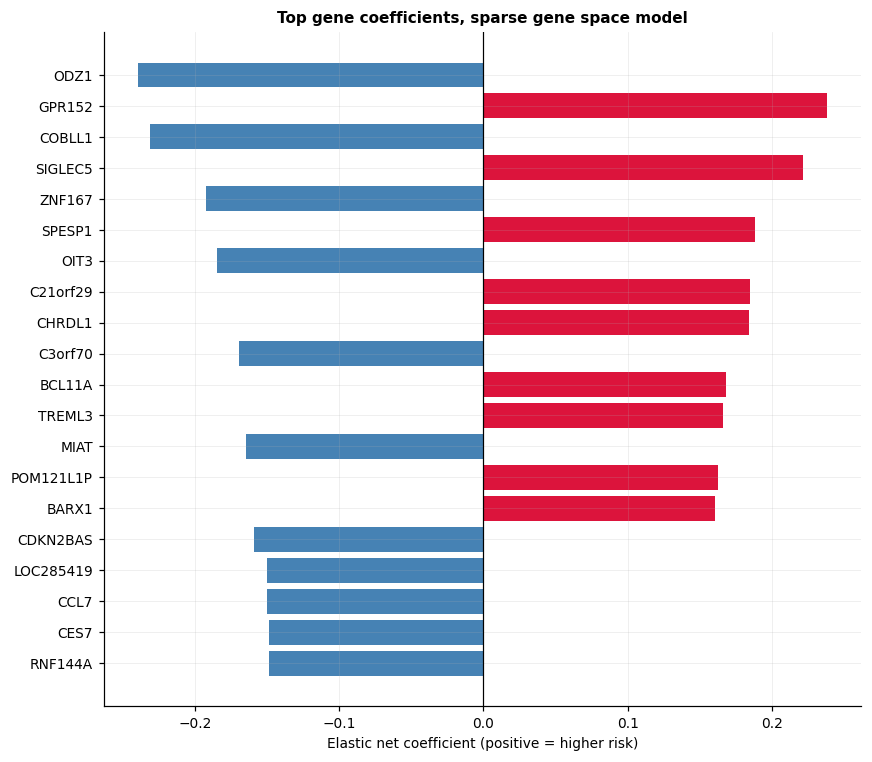

In [19]:
G_train = tx[:3].transform(X_train)          # imputed, filtered, standardized genes
G_test = tx[:3].transform(X_test)
enc_t = pr.ClinEncoder(["type"]).fit(C_train)
sc_t = StandardScaler().fit(enc_t.transform(C_train))
T_tr, T_te = sc_t.transform(enc_t.transform(C_train)), sc_t.transform(enc_t.transform(C_test))
feat = np.concatenate([genes_vt, enc_t.names()])
sparse_lr = LogisticRegression(penalty="elasticnet", solver="saga", l1_ratio=0.5, C=0.05,
                               class_weight="balanced", max_iter=3000, random_state=RANDOM_STATE)
sparse_lr.fit(np.hstack([G_train, T_tr]), y_train)
coef = sparse_lr.coef_.ravel()
print(f"Non zero coefficients: {(coef != 0).sum():,} of {len(coef):,}")
print(f"Test AUC: {roc_auc_score(y_test, sparse_lr.predict_proba(np.hstack([G_test, T_te]))[:, 1]):.4f}")
gene_coef = (pd.DataFrame({"feature": feat, "coef": coef})
             .assign(abs_coef=lambda d: d.coef.abs(), is_gene=lambda d: ~d.feature.str.startswith("type_"))
             .query("abs_coef > 0").sort_values("abs_coef", ascending=False).reset_index(drop=True))
gene_coef.to_csv(TAB_DIR / "sparse_model_coefficients.csv", index=False)
print(f"Tumor type indicators retained: {int((~gene_coef.is_gene).sum())} of {len(enc_t.names())}")
top20 = gene_coef[gene_coef.is_gene].head(20)
print(top20[["feature", "coef"]].to_string(index=False))

fig, ax = plt.subplots(figsize=(8, 7))
d_ = top20.iloc[::-1]
ax.barh(d_.feature, d_.coef, color=np.where(d_.coef > 0, "crimson", "steelblue"))
ax.axvline(0, color="k", lw=0.8)
ax.set_xlabel("Elastic net coefficient (positive = higher risk)")
ax.set_title("Top gene coefficients, sparse gene space model", fontweight="bold")
plt.tight_layout(); save_fig("figure7_sparse_genes"); plt.show()

## 13. Survival validation of the candidate genes

The five top ranked genes are evaluated on every patient not used to fit the sparse model: the
labelled test split plus all patients excluded from the binary analysis, so censored patients are
included. High and low expression are defined by the median **within each tumor type**, so the split
does not reflect differences in expression level between tumor types. Each gene is tested with a log
rank test stratified by tumor type and with a Cox model stratified by tumor type and adjusted for age,
sex and stage. p values are Benjamini Hochberg corrected across the five genes.

Validation patients: 5,559 (550 deaths), not used to select the genes
   gene  sparse_coef  stratified_logrank_p  adjusted_HR  HR_lo  HR_hi  adjusted_p  logrank_p_BH  adjusted_p_BH
   ODZ1      -0.2392                0.7653       0.9406 0.7917 1.1175      0.4860        0.9597         0.7638
 GPR152       0.2378                0.2575       1.0733 0.9010 1.2784      0.4281        0.6437         0.7638
 COBLL1      -0.2306                0.8634       1.0020 0.8434 1.1904      0.9822        0.9597         0.9822
SIGLEC5       0.2210                0.9597       0.9562 0.8046 1.1363      0.6110        0.9597         0.7638
 ZNF167      -0.1922                0.0354       0.8703 0.7326 1.0339      0.1140        0.1771         0.5700


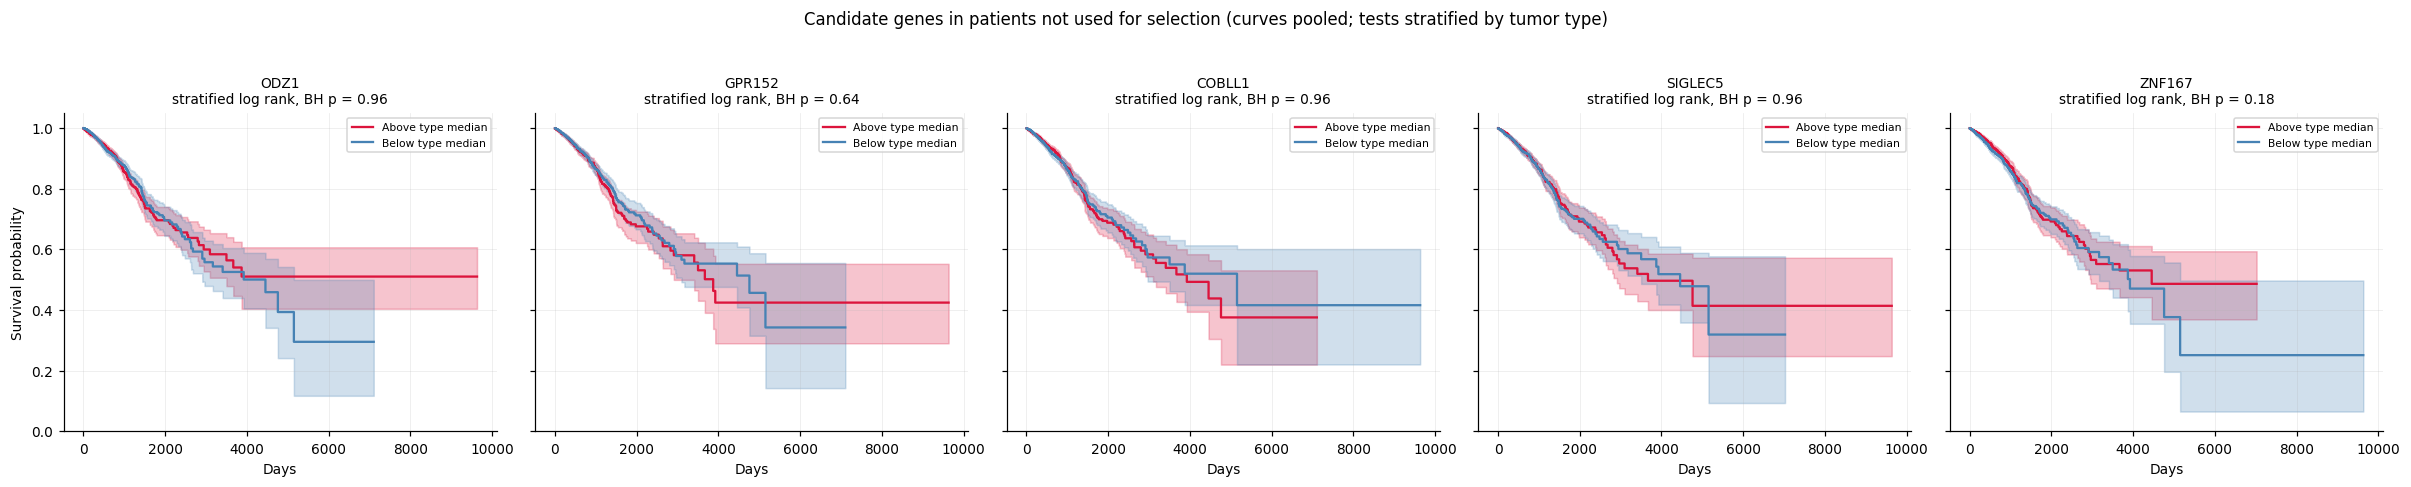

In [20]:
from lifelines import KaplanMeierFitter
from statsmodels.stats.multitest import multipletests


def stratified_logrank(T, E, g, strata):
    # log rank test summed over strata: observed minus expected and its variance
    o_e, var = 0.0, 0.0
    for s in np.unique(strata):
        m = strata == s
        t, e, gg = T[m], E[m], g[m]
        for u in np.unique(t[e == 1]):
            r = t >= u
            n, n1 = r.sum(), (r & gg).sum()
            d, d1 = ((t == u) & (e == 1)).sum(), ((t == u) & (e == 1) & gg).sum()
            o_e += d1 - d * n1 / n
            if n > 1:
                var += d * (n1 / n) * (1 - n1 / n) * (n - d) / (n - 1)
    chi2 = o_e ** 2 / var
    return chi2, float(st.chi2.sf(chi2, 1))


used = set(C.index[tr])
val_mask = ~clin.index.isin(used)
V_idx = np.where(val_mask)[0]
Tv, Ev, tyv = T_all[V_idx], E_all[V_idx], types_all[V_idx]
enc_cov = pr.ClinEncoder(["age", "sex", "stage"]).fit(C_all.iloc[V_idx])
cov = pd.DataFrame(enc_cov.transform(C_all.iloc[V_idx]), columns=enc_cov.names())
cov = cov.loc[:, cov.std() > 0]
top5 = top20.feature.head(5).tolist()
rows, HI = [], {}
for gname in top5:
    v = pd.Series(Xdf[gname].values[V_idx]); v = v.fillna(v.mean())
    hi = (v.values > v.groupby(tyv).transform("median").values)
    HI[gname] = hi
    chi2, p_lr = stratified_logrank(Tv, Ev, hi, tyv)
    d = cov.copy(); d["gene_high"] = hi.astype(float); d["T"], d["E"], d["type"] = Tv, Ev, tyv
    s = CoxPHFitter(penalizer=1e-4).fit(d, "T", "E", strata=["type"]).summary.loc["gene_high"]
    rows.append(dict(gene=gname, sparse_coef=float(top20.set_index("feature").loc[gname, "coef"]),
                     stratified_logrank_p=p_lr, adjusted_HR=s["exp(coef)"], HR_lo=s["exp(coef) lower 95%"],
                     HR_hi=s["exp(coef) upper 95%"], adjusted_p=s["p"]))
gv = pd.DataFrame(rows)
gv["logrank_p_BH"] = multipletests(gv.stratified_logrank_p, method="fdr_bh")[1]
gv["adjusted_p_BH"] = multipletests(gv.adjusted_p, method="fdr_bh")[1]
gv.to_csv(TAB_DIR / "table6_candidate_genes.csv", index=False)
print(f"Validation patients: {len(V_idx):,} ({int(Ev.sum()):,} deaths), not used to select the genes")
print(gv.round(4).to_string(index=False))

fig, axes = plt.subplots(1, 5, figsize=(22, 4.2), sharey=True)
kmf = KaplanMeierFitter()
for ax, gname in zip(axes, top5):
    hi = HI[gname]
    for mask, lbl, col in [(hi, "Above type median", "crimson"), (~hi, "Below type median", "steelblue")]:
        kmf.fit(Tv[mask], Ev[mask], label=lbl).plot_survival_function(ax=ax, ci_show=True, color=col)
    q = gv.set_index("gene").loc[gname, "logrank_p_BH"]
    ax.set_title(f"{gname}\nstratified log rank, BH p = {q:.2g}", fontsize=9)
    ax.set_xlabel("Days"); ax.set_ylim(0, 1.05); ax.legend(fontsize=7)
axes[0].set_ylabel("Survival probability")
plt.suptitle("Candidate genes in patients not used for selection (curves pooled; tests stratified by tumor type)", y=1.04)
plt.tight_layout(); save_fig("figureS_km_candidate_genes"); plt.show()

## 14. Supplementary analyses

### 14.1 Stability of principal component attribution

Four weightings of the selected components (logistic regression coefficients, random forest
importances, SVM permutation importances and Cox coefficients) are propagated through the same
loading matrix, and their top 50 genes are compared by Jaccard overlap.

        LR     RF    SVM    Cox
LR   1.000  0.351  0.282  0.064
RF   0.351  1.000  0.695  0.031
SVM  0.282  0.695  1.000  0.000
Cox  0.064  0.031  0.000  1.000

Mean off diagonal overlap: 0.237
Top 10 genes by unweighted sum of absolute loadings: EIF1AY, CYorf15A, UTY, PNLIPRP1, ZFY, KDM5D, HIST1H4H, TMSB4Y, TTTY15, DDX3Y


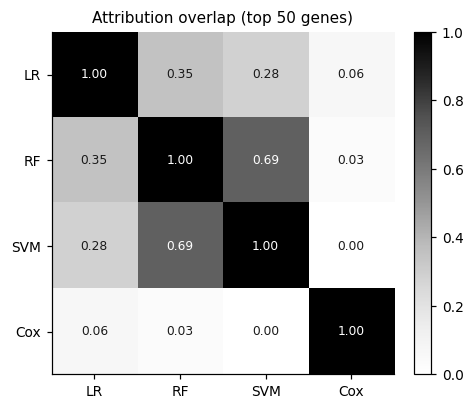

In [21]:
from sklearn.inspection import permutation_importance

sel = l1.get_support()
kept_loadings = pca.components_[sel]
sub = np.random.default_rng(RANDOM_STATE).choice(len(y_train), 1500, replace=False)
w = {
    "LR": np.abs(CLASSIFIERS[("transcriptome_only", "Logistic regression")].coef_).ravel(),
    "RF": CLASSIFIERS[("transcriptome_only", "Random forest")].feature_importances_,
    "SVM": np.clip(permutation_importance(CLASSIFIERS[("transcriptome_only", "SVM (RBF, Platt)")],
                                          Z_train[sub], y_train[sub], n_repeats=3, scoring="roc_auc",
                                          random_state=RANDOM_STATE).importances_mean, 0, None),
}
dcox = pd.DataFrame(Z_train, columns=[f"c{i}" for i in range(Z_train.shape[1])]); dcox["T"] = C_train.index.map(clin["OS.time"]).values
dcox["E"] = C_train.index.map(clin["OS"]).values
w["Cox"] = np.abs(CoxPHFitter(penalizer=0.05, l1_ratio=0.5).fit(dcox, "T", "E").params_.values)
proj = {k: np.abs(kept_loadings).T @ v for k, v in w.items()}
top_k = lambda s, k=50: set(genes_vt[np.argsort(s)[::-1][:k]])
keys = list(proj)
jac = pd.DataFrame([[len(top_k(proj[a]) & top_k(proj[b])) / len(top_k(proj[a]) | top_k(proj[b]))
                     for b in keys] for a in keys], index=keys, columns=keys)
off = jac.values[~np.eye(len(keys), dtype=bool)]
print(jac.round(3).to_string()); print(f"\nMean off diagonal overlap: {off.mean():.3f}")
unweighted = np.abs(kept_loadings).sum(0)
print("Top 10 genes by unweighted sum of absolute loadings:",
      ", ".join(genes_vt[np.argsort(unweighted)[::-1][:10]]))
fig, ax = plt.subplots(figsize=(4.4, 3.8))
im = ax.imshow(jac.values, cmap="Greys", vmin=0, vmax=1)
ax.set_xticks(range(4)); ax.set_xticklabels(keys); ax.set_yticks(range(4)); ax.set_yticklabels(keys)
for i in range(4):
    for j in range(4):
        ax.text(j, i, f"{jac.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8,
                color="white" if jac.iloc[i, j] > 0.5 else "#1a1a1a")
ax.grid(False); ax.set_title("Attribution overlap (top 50 genes)")
plt.colorbar(im, ax=ax, fraction=0.046); plt.tight_layout(); save_fig("figure8_attribution_stability"); plt.show()

### 14.2 Pathway enrichment (optional, needs `gseapy` and internet access)

Enrichment over the top 100 genes of the sparse model. Results are exploratory.

In [22]:
top100 = gene_coef[gene_coef.is_gene].feature.head(100).tolist()
print(f"Genes submitted: {len(top100)}")
try:
    import gseapy as gp
    enr = gp.enrichr(gene_list=top100, gene_sets=["GO_Biological_Process_2023", "KEGG_2021_Human"],
                     organism="human", outdir=None)
    res = enr.results.sort_values("P-value")
    res.to_csv(TAB_DIR / "enrichment_top100.csv", index=False)
    print(res[["Gene_set", "Term", "Overlap", "P-value", "Adjusted P-value"]].head(15).to_string(index=False))
    print(f"\nNominal p < 0.05: {(res['P-value'] < 0.05).sum()} | FDR < 0.05: {(res['Adjusted P-value'] < 0.05).sum()}")
except Exception as e:
    print(f"Enrichment skipped: {e}")

Genes submitted: 100


                  Gene_set                                                                                       Term Overlap  P-value  Adjusted P-value
GO_Biological_Process_2023                                            Glycosylceramide Catabolic Process (GO:0046477)     2/5 0.000245          0.056493
GO_Biological_Process_2023                                            Glycosylceramide Metabolic Process (GO:0006677)     2/5 0.000245          0.056493
           KEGG_2021_Human                                                                       Galactose metabolism    3/31 0.000492          0.032501
GO_Biological_Process_2023                                           Glycosphingolipid Catabolic Process (GO:0046479)     2/9 0.000871          0.133823
GO_Biological_Process_2023                                             Killing By Host Of Symbiont Cells (GO:0051873)    2/13 0.001862          0.214645
GO_Biological_Process_2023                                                    Cera

### 14.3 Shapley values at the component level (optional, needs `shap`)

PC15    0.0339
PC16    0.0313
PC1     0.0297
PC7     0.0259
PC6     0.0174
PC28    0.0166
PC5     0.0161
PC29    0.0149
PC13    0.0119
PC8     0.0111


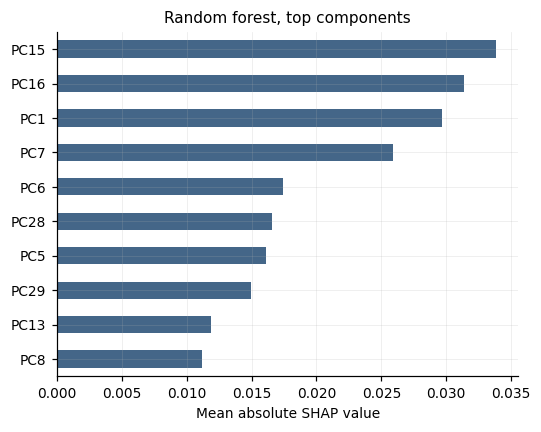

In [23]:
try:
    import shap
    rf_model = CLASSIFIERS[("transcriptome_only", "Random forest")]
    sv = shap.TreeExplainer(rf_model).shap_values(Z_test)
    sv = sv[:, :, 1] if getattr(sv, "ndim", 0) == 3 else (sv[1] if isinstance(sv, list) else sv)
    pc_names = [f"PC{i + 1}" for i in np.where(sel)[0]]
    imp = pd.Series(np.abs(sv).mean(0), index=pc_names).sort_values(ascending=False)
    print(imp.head(10).round(4).to_string())
    fig, ax = plt.subplots(figsize=(5, 4))
    imp.head(10)[::-1].plot.barh(ax=ax, color="#468")
    ax.set_xlabel("Mean absolute SHAP value"); ax.set_title("Random forest, top components")
    plt.tight_layout(); save_fig("figureS_shap_components"); plt.show()
except Exception as e:
    print(f"SHAP skipped: {e}")